Instalar Requisitos: 

In [1]:
#Download de requirements 
#!python ../scripts/dependencies.py install tools

#download de modulo  pt_core_news_lg no ambiente se não houver
#!python -m spacy download pt_core_news_lg

Para preparar a coletânea e gerar a estrutura de dados necessária, execute os scripts na seguinte ordem:

```bash
python src/crawler_dominio_publico_raw.py
python src/download_coletanea.py
```

Esses scripts irão baixar os dados do Domínio Público e organizar a coletânea na seguinte estrutura:

```text
Dataset/
├── metadata/
└── raw/
```


Imports

In [2]:
import re
import os 
import glob
import spacy
import pymupdf
import unicodedata
import pandas as pd 
import plotly.express as px
from collections import Counter
import plotly.graph_objects as go
from difflib import SequenceMatcher
from plotly.subplots import make_subplots

### Carregando dados

In [3]:
BASE_PATH = "../" # pasta superior no nivel da pasta de exploração 

df_coletanea_pdfs = pd.read_csv(
    f"{BASE_PATH}"
    "Dataset/metadata/obras_machado_assis_deduplicadas.csv"
)
df_coletanea_pdfs["pdf_path"] = df_coletanea_pdfs["pdf_path"].apply(
    lambda x: os.path.join(BASE_PATH, x)
    if pd.notna(x)
    else None
)
df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Carteira.pdf
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Cartomante.pdf
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Causa_Secreta.pdf
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_chave.pdf
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Chinela_Turca.pdf
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Viver!.pdf
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Várias_Histórias.pdf
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Vênus!_divina_vênus!.pdf
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Última_receita.pdf


In [4]:
paths = df_coletanea_pdfs["pdf_path"].dropna()

existentes = paths.apply(os.path.isfile)

print(f"{existentes.sum()} de {len(paths)} existentes")

if not existentes.all():
    print("\nNão encontrados:")
    for path in paths[~existentes]:
        print(path)

257 de 257 existentes


Um pdf não existia dado que em dropna perdemos 1 amostra de 258 para 257 , validando qual :

In [5]:
df_coletanea_pdfs.loc[df_coletanea_pdfs["pdf_path"].isna()]

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
167,O Rei dos Caiporas,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"0,00 KB",8240,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,None


procurando na fonte o pdf nao esta disponivel no server: 

https://dominiopublico.mec.gov.br/pesquisa/DetalheObraForm.do?select_action=&co_obra=17481

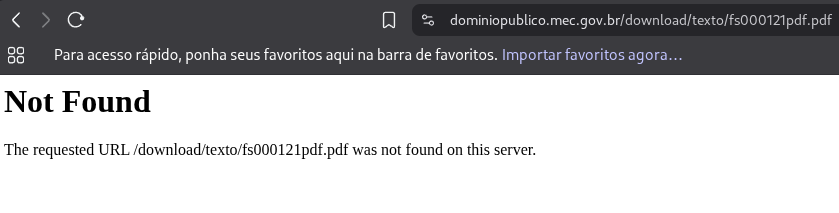

**TODO:** necessário atualizar o crawler de download para lidar com casos em que não há PDFs disponíveis.

Por ora, remover esses registros do DataFrame.


In [6]:
df_coletanea_pdfs.dropna(inplace=True)
df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Carteira.pdf
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Cartomante.pdf
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Causa_Secreta.pdf
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_chave.pdf
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/A_Chinela_Turca.pdf
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Viver!.pdf
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Várias_Histórias.pdf
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Vênus!_divina_vênus!.pdf
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,../Dataset/raw/Última_receita.pdf


### Analise quantitativa bruta

removendo colunas não necessárias para essa analise

In [7]:
df_coletanea_infos = df_coletanea_pdfs.copy()
df_coletanea_infos.drop(columns=["formato","url_detalhe","autor","url_download","tamanho","downloads_encontrados"], inplace=True)
df_coletanea_infos

,titulo,fonte,acessos,pdf_path
0,A Carteira,[ua] Universidade da Amazônia - UNAMA,114102,../Dataset/raw/A_Carteira.pdf
1,A Cartomante,[ua] Universidade da Amazônia - UNAMA,154851,../Dataset/raw/A_Cartomante.pdf
2,A Causa Secreta,[ua] Universidade da Amazônia - UNAMA,53202,../Dataset/raw/A_Causa_Secreta.pdf
3,A chave,[fs] Universidade Federal de Santa Catarina - ...,55648,../Dataset/raw/A_chave.pdf
4,A Chinela Turca,[bv] Biblioteca Virtual do Estudante Brasileir...,63578,../Dataset/raw/A_Chinela_Turca.pdf
...,...,...,...,...
253,Viver!,[bv] Biblioteca Virtual do Estudante Brasileir...,11632,../Dataset/raw/Viver!.pdf
254,Várias Histórias,[bv] Biblioteca Virtual do Estudante Brasileir...,24726,../Dataset/raw/Várias_Histórias.pdf
255,Vênus! divina vênus!,[fs] Universidade Federal de Santa Catarina - ...,8184,../Dataset/raw/Vênus!_divina_vênus!.pdf
256,Última receita,[fs] Universidade Federal de Santa Catarina - ...,5506,../Dataset/raw/Última_receita.pdf


##### Extraindo metricas estatisticas do corpus textual 

In [8]:
def extrair_metricas_pdf(pdf_path):
    doc = pymupdf.open(pdf_path)

    qtd_paginas = doc.page_count
    qtd_palavras = 0

    for page in doc:
        texto = page.get_text()
       
        palavras = re.findall(r"\b\w+\b", texto, flags=re.UNICODE)
        qtd_palavras += len(palavras)

    doc.close()

    return pd.Series({
        "count_pages": qtd_paginas,
        "count_words": qtd_palavras,
    })

In [9]:
df_coletanea_infos[
    [
        "count_pages",
        "count_words",
    ]
] = df_coletanea_infos["pdf_path"].apply(
    extrair_metricas_pdf
)

In [10]:
df_coletanea_infos

,titulo,fonte,acessos,pdf_path,count_pages,count_words
0,A Carteira,[ua] Universidade da Amazônia - UNAMA,114102,../Dataset/raw/A_Carteira.pdf,4,1375
1,A Cartomante,[ua] Universidade da Amazônia - UNAMA,154851,../Dataset/raw/A_Cartomante.pdf,8,3280
2,A Causa Secreta,[ua] Universidade da Amazônia - UNAMA,53202,../Dataset/raw/A_Causa_Secreta.pdf,8,3497
3,A chave,[fs] Universidade Federal de Santa Catarina - ...,55648,../Dataset/raw/A_chave.pdf,17,6648
4,A Chinela Turca,[bv] Biblioteca Virtual do Estudante Brasileir...,63578,../Dataset/raw/A_Chinela_Turca.pdf,10,3669
...,...,...,...,...,...,...
253,Viver!,[bv] Biblioteca Virtual do Estudante Brasileir...,11632,../Dataset/raw/Viver!.pdf,6,2575
254,Várias Histórias,[bv] Biblioteca Virtual do Estudante Brasileir...,24726,../Dataset/raw/Várias_Histórias.pdf,56,47267
255,Vênus! divina vênus!,[fs] Universidade Federal de Santa Catarina - ...,8184,../Dataset/raw/Vênus!_divina_vênus!.pdf,9,3467
256,Última receita,[fs] Universidade Federal de Santa Catarina - ...,5506,../Dataset/raw/Última_receita.pdf,7,1972


In [11]:
print(df_coletanea_infos["count_words"].mean())
print(df_coletanea_infos["count_words"].sum())

9054.2140077821
2326933


Estamos olhando para 257 obras: 
que somam : 
* 2.326.933 palavras escritas ! Haja Tinta!
* Em uma média de 9054.21 palavras por obra

##### Vocabulário

Vamos olhar quantas palavras compunham o vocabulário de Machado de Assis?

Aqui a análise fica mais difícil, porque essas obras em domínio público podem não ser totalmente fiéis aos manuscritos originais e podem refletir adaptações ao acordo ortográfico vigente na época em que foram disponibilizadas pelas fontes responsáveis.


In [12]:
def contar_palavras_corpus(df, tamanho_minimo=0):
    contador = Counter()

    for pdf_path in df["pdf_path"].dropna():

        with pymupdf.open(pdf_path) as doc:

            for page in doc:
                texto = page.get_text().lower()

                palavras = re.findall(
                    r"\b\w+\b",
                    texto,
                    flags=re.UNICODE,
                )

                palavras = [
                    palavra
                    for palavra in palavras
                    if len(palavra) > tamanho_minimo
                ]

                contador.update(palavras)

    return contador


contador_palavras = contar_palavras_corpus(
    df_coletanea_infos
)

55,937 palavras unicas !  De acordo com  a wikipedia em https://pt.wikipedia.org/wiki/L%C3%ADngua_portuguesa 

A academia brasileira de letras estima 356mil unidades lexicais (palavra isolada) na lingua portuguesa 

nisso Machado de assis cobriu 15,71% dese corpo lexical , o bravo 

In [13]:
print("Total de palavras:", contador_palavras.total())
print("Mais frequentes:", contador_palavras.most_common(20))

Total de palavras: 2326933
Mais frequentes: [('a', 91720), ('que', 84103), ('de', 77644), ('o', 72204), ('e', 69288), ('não', 42942), ('se', 32763), ('um', 28809), ('do', 28377), ('da', 24716), ('os', 21710), ('é', 21291), ('uma', 19108), ('com', 19054), ('lhe', 18353), ('em', 17783), ('para', 16883), ('as', 16530), ('mas', 16329), ('me', 15271)]


Bom vendo as mais usadas são conectores e artigos, vamos fazer um filtro de palavras maiores que 3 letras, pra termos uma ideia melhor do que ele mais usava 

In [14]:
contador_palavras = contar_palavras_corpus(
    df_coletanea_infos, tamanho_minimo=3
)

print(
    f"Palavras únicas (> 3 letras): "
    f"{len(contador_palavras):,}"
)

Palavras únicas (> 3 letras): 54,735


In [15]:
contador_palavras.most_common(20)

[('para', 16883),
 ('mais', 10939),
 ('como', 9588),
 ('disse', 6347),
 ('quando', 5440),
 ('casa', 4965),
 ('depois', 4634),
 ('tudo', 4493),
 ('tinha', 4454),
 ('ainda', 4353),
 ('tempo', 4266),
 ('nada', 3987),
 ('muito', 3965),
 ('olhos', 3957),
 ('minha', 3716),
 ('mesmo', 3649),
 ('outro', 3602),
 ('outra', 3496),
 ('estava', 3437),
 ('esta', 3357)]

Bom, ainda temos o problema dos conectivos e das diferentes formas verbais, mas já estamos nos aproximando de uma estrutura mais representativa dos substantivos.

Agora faremos um filtro mais orientado, mantendo apenas substantivos e adjetivos.

Hora de trazer um calibre mais pesado e usar bibliotecas de NLP para nos auxiliar na classificação das palavras como substantivos ou adjetivos.


In [16]:
nlp = spacy.load(
    "pt_core_news_lg",
    disable=["ner", "parser"],
)
def contar_termos_corpus(df):
    contador = Counter()

    pos_validas = {
        "NOUN",   # substantivos
        "ADJ",    # adjetivos
    }

    for pdf_path in df["pdf_path"].dropna():

        with pymupdf.open(pdf_path) as doc:
            texto = "\n".join(
                page.get_text()
                for page in doc
            )

        for doc_spacy in nlp.pipe(
            [texto],
            batch_size=1,
        ):
            termos = [
                token.lemma_.lower()
                for token in doc_spacy
                if (
                    token.pos_ in pos_validas
                    and token.is_alpha
                    and len(token.lemma_) > 2
                )
            ]

            contador.update(termos)

    return contador

contador_termos = contar_termos_corpus(
    df_coletanea_infos
)

In [17]:
contador_termos.most_common(20)

[('dia', 5924),
 ('casa', 4900),
 ('tempo', 4709),
 ('vez', 4477),
 ('bom', 4139),
 ('olho', 4035),
 ('mesmo', 4033),
 ('homem', 3957),
 ('grande', 3780),
 ('primeiro', 3193),
 ('coisa', 3190),
 ('mão', 3142),
 ('ano', 3116),
 ('vida', 2908),
 ('palavra', 2881),
 ('moça', 2840),
 ('amigo', 2833),
 ('amor', 2671),
 ('carta', 2588),
 ('coração', 2546)]

Agora foi! Foi legal de ver e dá para notar certa simplicidade nas palavras mais comuns. Acho que já era esperado — ninguém vai escrever “paralelepípedo” toda hora kkk.

Antes de seguirmos vamos ver as menos comuns: 

In [18]:
contador_termos.most_common()[-20:]

[('grosser', 1),
 ('embrulhara', 1),
 ('célere', 1),
 ('transtornar', 1),
 ('humilhar', 1),
 ('enraivecido', 1),
 ('áugur', 1),
 ('farandolagem', 1),
 ('habitarás', 1),
 ('domina', 1),
 ('gesso', 1),
 ('delgadinho', 1),
 ('roa', 1),
 ('pombinha', 1),
 ('palminha', 1),
 ('sonetinhos', 1),
 ('terrífico', 1),
 ('pecurrucha', 1),
 ('cacetar', 1),
 ('trajado', 1)]

Aqui estão algunas das mais parrudas! Farandolagem, já tinha visto essa antes?  

Se não, vai lá dar uma olhada :

https://www.dicio.com.br/farandolagem/

##### Graficos 

distribuição dos dados de cada pdf

In [19]:
metricas = {
    "count_words": "Quantidade de palavras",
}


def plot_distribuicao(df, coluna, titulo):

    dados = pd.to_numeric(
        df[coluna],
        errors="coerce",
    ).dropna()

    media = dados.mean()
    mediana = dados.median()

    fig = make_subplots(
        rows=1,
        cols=2,
        column_widths=[0.75, 0.25],
        subplot_titles=[
            "Distribuição",
            "Boxplot",
        ],
    )

    fig.add_trace(
        go.Histogram(
            x=dados,
            nbinsx=20,
            hovertemplate=(
                f"{titulo}: %{{x:,.0f}}"
                "<br>Obras: %{y}"
                "<extra></extra>"
            ),
        ),
        row=1,
        col=1,
    )

    fig.add_vline(
        x=media,
        line_dash="dash",
        annotation_text=f"Média: {media:,.1f}",
        annotation_position="top",
        row=1,
        col=1,
    )

    fig.add_vline(
        x=mediana,
        line_dash="dot",
        annotation_text=f"Mediana: {mediana:,.1f}",
        annotation_position="bottom",
        row=1,
        col=1,
    )

    fig.add_trace(
        go.Box(
            y=dados,
            boxpoints="outliers",
            name="",
            hovertemplate=(
                f"{titulo}: %{{y:,.0f}}"
                "<extra></extra>"
            ),
        ),
        row=1,
        col=2,
    )

    fig.update_xaxes(
        title_text=titulo,
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text="Quantidade de obras",
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text=titulo,
        row=1,
        col=2,
    )

    fig.update_layout(
        template="plotly_white",
        height=550,
        width=1200,
        showlegend=False,
        bargap=0.05,
        title={
            "text": f"{titulo} — {len(dados)} obras",
            "x": 0.5,
        },
    )

    fig.show()


for coluna, titulo in metricas.items():
    plot_distribuicao(
        df_coletanea_infos,
        coluna,
        titulo,
    )

Através dessa analise visual da quantidade de palavras usadas por Machado em seus livros e contos é interessante notarmos o quão desbalanceado é a distribuição e isso indica um fato para os conhecedores de Assis, de que ele foi um autor muito mais de contos e crônicas do que de obras completas, a maioria de seus contos era publicada em jornais e folhetins de epoca

In [20]:
desvio_padrao_palavras = df_coletanea_infos["count_words"].std()
print(desvio_padrao_palavras)

15324.06553498215


E apesar de seus folhetins e contos curtos, o desvio padrao de aproximadamente 15.324 palavras, demonstra que quando o velho pegava pra escrever um livro, escrevia mesmo e não poupava palavras . O máximo da coletanea foi 124.721 palavras na obra "A semana". EU como leitor confesso que não conhecia essa 


E isso me traz a pergunta, mais palavras é mais qualidade? Se tratarmos qualidade como sendo quantos acessos essa obra teve em dominio publico, podemos fazer uma correlação entre quantidade de palavras e acessos no portal de dominio publico para responder essa questão 

In [21]:
df_plot = df_coletanea_infos.copy()

df_plot["count_words"] = pd.to_numeric(
    df_plot["count_words"],
    errors="coerce",
)

df_plot["acessos"] = pd.to_numeric(
    df_plot["acessos"],
    errors="coerce",
)

df_plot = df_plot.dropna(
    subset=["count_words", "acessos"]
)


correlacao = df_plot["count_words"].corr(
    df_plot["acessos"]
)


fig = px.scatter(
    df_plot,
    x="count_words",
    y="acessos",
    hover_name="titulo",
    hover_data=[
        "count_pages",
        "fonte",
    ],
    trendline="ols",
    title=(
        "Quantidade de palavras × Acessos"
        f"<br><sup>Correlação de Pearson: {correlacao:.3f}</sup>"
    ),
    labels={
        "count_words": "Quantidade de palavras",
        "acessos": "Número de acessos",
    },
)

fig.update_traces(
    marker={
        "size": 9,
        "opacity": 0.7,
    }
)

fig.update_layout(
    template="plotly_white",
    height=650,
    width=1000,
    title={
        "x": 0.5,
        "xanchor": "center",
    },
)

fig.show()

In [22]:
corr_pearson = df_coletanea_infos[
    ["acessos", "count_words"]
].corr(
    method="pearson"
).loc[
    "acessos",
    "count_words"
]

corr_spearman = df_coletanea_infos[
    ["acessos", "count_words"]
].corr(
    method="spearman"
).loc[
    "acessos",
    "count_words"
]


print(
    f"Correlação de Pearson:  {corr_pearson:.3f}"
)

print(
    f"Correlação de Spearman: {corr_spearman:.3f}"
)

Correlação de Pearson:  0.107
Correlação de Spearman: -0.040


Com os coeficientes de correlação:

* **Pearson:** 0,107
* **Spearman:** -0,040

podemos dizer que, neste corpus, praticamente não há relação linear entre a quantidade de palavras e o número de acessos. O coeficiente de Spearman, também muito próximo de zero, reforça que não existe uma relação monotônica relevante entre essas duas variáveis.

Portanto, dentro da definição de qualidade que adotamos anteriormente, escrever mais também não significa necessariamente ter mais qualidade.

Inclusive, a obra *A Semana* está sambando praticamente em cima da linha de tendência entre palavras e acessos, mas está longe de ser a melhor obra segundo a nossa métrica.

Se observarmos a obra com mais acessos, encontramos *A Cartomante*, com 3.280 palavras e 154.851 acessos: campeã da coletânea nessa métrica e, particularmente, uma das minhas preferidas.

Mas há algo interessante na forma como as obras se concentram em textos relativamente curtos. Isso reforça uma característica que já observamos anteriormente: muitas das obras de Machado presentes neste corpus possuem poucas palavras e, consequentemente, várias das obras mais acessadas também são curtas.

Com o gráfico anterior, observamos que, das 257 obras da coletânea:

* **220 possuem até 5.000 palavras.**

Isso significa que **85,60% das obras analisadas possuem, no máximo, 5.000 palavras**.

A mediana reforça ainda mais essa concentração: 50% das obras possuem até 4.285 palavras. Entre esse ponto e o corte de 5.000 palavras, que já contempla 85,60% do corpus, há um aumento de apenas **715 palavras**.

Em outras palavras, avançamos de 50% para 85,60% das obras — um acréscimo de 35,60 pontos percentuais do corpus — aumentando o limite de tamanho em apenas 715 palavras. Isso mostra como grande parte das obras está fortemente concentrada em uma faixa relativamente estreita de textos curtos.


Dado que analisamos as obras com qualidade= quantidade de acessos vejamos o  top 10 livros por acesso 

In [23]:
def limite_superior_outlier(serie):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    return q3 + 1.5 * iqr

top10 = (
    df_coletanea_infos
    .assign(
        acessos=pd.to_numeric(
            df_coletanea_infos["acessos"],
            errors="coerce",
        )
    )
    .dropna(subset=["acessos"])
    .nlargest(10, "acessos")
    .sort_values("acessos")
    .copy()
)

lim_sup_words = limite_superior_outlier(
    df_coletanea_infos["count_words"]
)

top10["outlier_words"] = (
    top10["count_words"] > lim_sup_words
)

top10["label_words"] = top10.apply(
    lambda x: (
        f"{x['count_words']:,.0f} ★"
        if x["outlier_words"]
        else f"{x['count_words']:,.0f}"
    ),
    axis=1,
)

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "Número de acessos",
        "Quantidade de palavras",
    ],
    horizontal_spacing=0.18,
)


fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["acessos"],
        orientation="h",
        text=top10["acessos"],
        texttemplate="%{text:,.0f}",
        textposition="outside",
        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Acessos: %{x:,.0f}"
            "<extra></extra>"
        ),
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["count_words"],
        orientation="h",
        text=top10["label_words"],
        textposition="outside",
        customdata=top10[["acessos", "outlier_words"]],
        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Palavras: %{x:,.0f}"
            "<br>Acessos: %{customdata[0]:,.0f}"
            "<br>Outlier: %{customdata[1]}"
            "<extra></extra>"
        ),
    ),
    row=1,
    col=2,
)


fig.update_xaxes(
    title_text="Número de acessos",
    row=1,
    col=1,
)

fig.update_xaxes(
    title_text="Quantidade de palavras",
    row=1,
    col=2,
)


fig.update_layout(
    template="plotly_white",
    height=650,
    width=1400,
    showlegend=False,
    title={
        "text": (
            "Top 10 obras mais acessadas"
            "<br><sup>"
            "★ indica outlier em quantidade de palavras "
            "segundo 1,5 × IQR do corpus"
            "</sup>"
        ),
        "x": 0.5,
        "xanchor": "center",
    },
)

fig.show()

Bom, avaliando o top 10 da nossa métrica e suas respectivas quantidades de palavras, apenas 3 das 10 obras são outliers e possuem mais de 5 mil palavras.

Isso significa que 70% das obras mais bem colocadas têm menos de 5 mil palavras. O homem era talentoso com o pouco que escrevia!

Chega até a parecer que existe uma correlação negativa entre a quantidade de palavras e o número de acessos, mas ela não existe. Essa impressão surge porque estamos olhando para um recorte específico dos dados, sob uma métrica específica e utilizando um ranking arbitrário como aproximação de qualidade.

No caso estamos olhando qualidade como mais acessos.  Isto é uma métrica totalmente fabricada que definimos para a nossa análise, a essa métrica não tem relação com quantas palavras ele usava em cada obra que escrevia, e em nosso grafico, se esquecessemos o que era a métrica e as analises anteriores poderiamos achar que só é bom aquilo que é curto 

Esse é um bom exemplo de como métricas e indicadores são abstrações úteis, mas perigosas quando passam a ser confundidas com o fenômeno que pretendem representar.

### Analise Semantica Estrutural

Avaliando algumas amostras de documentos:

In [24]:
path = df_coletanea_pdfs.loc[1,"pdf_path"]
print("Registro:")
print(df_coletanea_pdfs.loc[1])
doc = pymupdf.open(path)
for page in doc: 
    text = page.get_text()
    print(text)

    break 

Registro:
titulo                                                        A Cartomante
autor                                                     Machado de Assis
fonte                                [ua] Universidade da Amazônia - UNAMA
formato                                                               .pdf
tamanho                                                           39,64 KB
acessos                                                             154851
url_detalhe              https://dominiopublico.mec.gov.br/pesquisa/Det...
url_download             https://dominiopublico.mec.gov.br/pesquisa/Det...
downloads_encontrados                                                    1
pdf_path                                   ../Dataset/raw/A_Cartomante.pdf
Name: 1, dtype: object
www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-31

Necessária uma limpeza nesses dados, aparentemente , todos eles começam com um header indicando questões da obra, quem publicou quando e onde  

e.g: 

* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Questão_de_vaidade.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Questão de vaidade, de Machado de Assis
Edição referência: http://www2.uol.com.br/machadodeassis
Publicado originalmente em Jornal das Famílias 1864
 

* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Hoje_Avental,_amanhã_Luva.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Hoje Avental, Amanhã Luva, de Machado de Assis.
Edição de referência: Teatro de Machado de Assis, de Machado de Assis
Martins Fontes, 2003, São Paulo


* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/A_Cartomante.pdf')
www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

www.nead.unama.br

Se quisermos trabalhar com esses dados, é bom atuar em um removedor de "começo" com infos não relacionadas a obra 

Minha primeira tentativa sera  montar uma heuristica que remova header, quem sabe de resultados

In [25]:
df_coletanea_pdfs.reset_index(inplace=True)

In [26]:
sample = df_coletanea_pdfs.sample(
    n=10,
    random_state=42,
)

for _, row in sample.iterrows():

    titulo = row["titulo"]
    path = row["pdf_path"]

    print("=" * 50)

    print(row["fonte"])
    print(titulo)

    print()

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    print(texto)

[fs] Universidade Federal de Santa Catarina - UFSC
O Protocolo

LITERATURA BRASILEIRA
Textos literários em meio eletrônico
O Protocolo, de Machado de Assis.
Edição de referência: Teatro de Machado de Assis, de Machado de Assis
Martins Fontes, 2003, São Paulo
 
CARTA A QUINTINO BOCAIÚVA
 
Meu amigo,
Vou publicar as minhas duas comédias de estréia; e não quero fazê-lo sem conselho da 
tua competência.
Já uma crítica benévola e carinhosa, em que tomaste parte, consagrou a estas duas 
composições palavras de louvor e animação.
Sou imensamente reconhecido, por tal, aos meus colegas da imprensa.
Mas o que recebeu na cena o batismo do aplauso pode, sem inconveniente, ser 
trasladado para o papel? A diferença entre os dois meios de publicação não modifica o 
juízo, não altera o valor da obra?
É para a solução destas dúvidas que recorro à tua autoridade literária.
O juízo da imprensa viu nestas duas comédias - simples tentativas de autor tímido e 
receoso. Se a minha afirmação não envolve suspe

Avaliando manualmente, percebi que sempre que a fonte é a Universidade do Amazonas, a primeira pagina é o header, vamos validar se removendo a primeira pagina nesses casos ficamos so com o texto 

In [27]:
FONTE_RESOLVIDA = "Universidade da Amazônia"

df_unama = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        FONTE_RESOLVIDA,
        case=False,
        regex=False,
    )
]

print(f"Universidade da Amazônia: {len(df_unama)} obras")

for _, row in df_unama.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    print("\n" + "=" * 100)
    print(titulo)
    print("=" * 100)

    with pymupdf.open(path) as doc:
        if doc.page_count > 1:
            print(doc[1].get_text())

Universidade da Amazônia: 54 obras

A Carteira
www.nead.unama.br
2
A Carteira
de Machado de Assis
...De repente, Honório olhou para o chão e viu uma carteira.
Abaixar-se, apanhá-la e guardá-la foi obra de alguns instantes. Ninguém o
viu, salvo um homem que estava à porta de uma loja, e que, sem o conhecer, lhe
disse rindo:
— Olhe, se não dá por ela; perdia-a de uma vez.
    
— É verdade, concordou Honório envergonhado.
    
Para avaliar a oportunidade desta carteira, é preciso saber que Honório tem
de pagar amanhã uma dívida, quatrocentos e tantos mil-réis, e a carteira trazia o
bojo recheado. A dívida não parece grande para um homem da posição de Honório,
que advoga; mas todas as quantias são grandes ou pequenas, segundo as
circunstâncias, e as dele não podiam ser piores. Gastos de família excessivos, a
princípio por servir a parentes, e depois por agradar à mulher, que vivia aborrecida
da solidão; baile daqui, jantar dali, chapéus, leques, tanta cousa mais, que não havia
remédio senã

Pra esses casos, validando funcionou hein, temos a primeira heuristica de filtro de header

Avaliando o restante, fica claro que cada fonte, tem seu header padrão com informações sobre a obra, antes do começo da história, irei atuar, na remoção destes com heuristicas dado os resultados que tivemos com essa abordagem tirando os header da fonte Universidade do Amazonas. 


Começar vendo quantas fontes, tem e ir removendo da que mais tem pra que menos tem obras, pra facilitar o trabalho de investigação manual, conforme vai passando 

In [28]:
df_coletanea_pdfs["fonte"].value_counts()

fonte
[fs] Universidade Federal de Santa Catarina - UFSC       137
[bv] Biblioteca Virtual do Estudante Brasileiro / USP     60
[ua] Universidade da Amazônia - UNAMA                     54
[bn] Fundação Biblioteca Nacional                          4
[bi] Biblioteca Virtual de Literatura                      1
[ub] Universidade de Brasília                              1
Name: count, dtype: int64

Tendo em vista que o da Amazonia já foi, irei atuar nos outros a começar da [fs] Universidade Federal de Santa Catarina - UFSC

#### Avaliando fonte: [fs] Universidade Federal de Santa Catarina - UFSC

In [29]:
df_fs = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        "Universidade Federal de Santa Catarina",
        case=False,
        regex=False,
    )
]

In [30]:
sample_fs = df_fs.sample(
    n=3,
    random_state=42,
)

for _, row in sample_fs.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto[:500])


TÍTULO: Terpsícore
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Terpsícore, de Machado de Assis
Edição referência: http://www2.uol.com.br/machadodeassis
Publicado originalmente em Gazeta de Notícias 1886
Glória, abrindo os olhos, deu com o marido sentado na cama, olhando para a parede, e 
disse-lhe que se deitasse, que dormisse, ou teria de ir para a oficina com sono.
— Que dormir o quê, Glória? Já deram seis horas.
— Jesus! Há muito tempo?
— Deram agora mesmo.
Glória arredou de cima de si a colcha d

TÍTULO: Só
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Só! , de Machado de Assis
Edição de Referência: Obra Completa, de Machado de Assis, vol. II,
Nova Aguilar, Rio de Janeiro, 1994.
BONIFÁCIO, depois de fechar a porta, guardou a chave, atravessou o jardim e meteu-se 
em casa. Estava só, finalmente só. A frente da casa dava para uma rua pouco 
freqüentada e quase sem moradores. A um dos lados da chácara corria outra rua. Creio 
que tudo isso era para os lado

O padrão identificado nos documentos da UFSC é a presença de um cabeçalho relativamente regular nas primeiras linhas, composto por informações institucionais e bibliográficas, como “Literatura Brasileira”, “Textos literários em meio eletrônico”, referência à obra de Machado de Assis, edição de referência, “Obra Completa”, “Texto-fonte” e pequenas referências entre colchetes. Em alguns PDFs, esse cabeçalho também aparece quebrado pela extração, como em Ob seguido de ra Completa.

A limpeza usa esses padrões para identificar até onde vai o cabeçalho e remove apenas esse trecho inicial. A partir da primeira linha que deixa de corresponder aos padrões conhecidos, o restante do texto é preservado como conteúdo efetivo da obra.

In [31]:
def limpar_inicio_ufsc(texto):
    linhas = [
        linha.strip()
        for linha in texto.splitlines()
        if linha.strip()
    ]

    inicio_conteudo = 0

    for i, linha in enumerate(linhas[:15]):
        linha_lower = linha.lower()

        # Caso quebrado pelo PDF:
        # "Ob"
        # "ra Completa, de Machado..."
        if (
            linha_lower == "ob"
            and i + 1 < len(linhas)
            and linhas[i + 1].lower().startswith("ra completa")
        ):
            inicio_conteudo = i + 2
            continue

        # Referências curtas, ex:
        # [JF. nov. 1864]
        referencia_colchetes = re.match(
            r"^\[[^\]]+\]$",
            linha.strip(),
        )

        eh_header = (
            "literatura brasileira" in linha_lower
            or "textos literários em meio eletrônico" in linha_lower
            or "de machado de assis" in linha_lower
            or "edição de referência" in linha_lower
            or "edição referência" in linha_lower
            or "publicado originalmente" in linha_lower
            or "nova aguilar" in linha_lower
            or "martins fontes" in linha_lower

            or "obra completa" in linha_lower
            or "texto-fonte:" in linha_lower
            or referencia_colchetes
        )

        if eh_header:
            inicio_conteudo = i + 1
            continue

        if i > 0:
            anterior = linhas[i - 1].lower()

            if (
                "edição de referência" in anterior
                or "edição referência" in anterior
                or "nova aguilar" in anterior
                or "obra completa" in anterior
                or "texto-fonte:" in anterior

                # cobre:
                # Ob
                # ra Completa...
                or anterior == "ob"
            ):
                inicio_conteudo = i + 1
                continue

        if inicio_conteudo > 0:
            break

    return "\n".join(
        linhas[inicio_conteudo:]
    ).strip()

In [32]:
for _, row in df_fs.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]
    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    texto_limpo = limpar_inicio_ufsc(texto)

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto_limpo[:100])


TÍTULO: A chave
poético: aurora, com seus róseos dedos... A maneira simples é o que melhor me conviria
a mim, ao lei

TÍTULO: A Herança
Venância tinha dois sobrinhos, Emílio e Marcos; o primeiro de vinte e oito, o segundo de
trinta e qu

TÍTULO: A idéia do Ezequiel Maia
revestimento ilusório que dá o aspecto material às cousas. Ezequiel era idealista. Negava
abertament

TÍTULO: A Inglezinha Barcelos
Eram trintonas. Cândida era casada, Joaninha solteira. Antes deste dia de março de
1886, viram-se pe

TÍTULO: A melhor das noivas
O sorriso dos velhos é porventura uma das coisas mais adoráveis do mundo. Não o era
porém o de João 

TÍTULO: A mulher Pálida
I
Rangeu enfim o último degrau da escada ao peso do vasto corpo do major Bento. O major
deteve-se um

TÍTULO: A mágoa do Infeliz Cosme
I
Imensa e profunda foi a mágoa do infeliz Cosme. Depois de três anos de não interrompida
ventura, f

TÍTULO: A Pianista
Tinha vinte e dois anos e era professora de piano. Era alta, formosa, morena e modes

Validando manualmente está satisfatório também 

#### Avaliando fonte:  [bn] Fundação Biblioteca Nacional


In [33]:
FONTE_RESOLVIDA = "Fundação Biblioteca Nacional"
df_bn = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        FONTE_RESOLVIDA,
        case=False,
        regex=False,
    )
]

In [34]:
sample_bn = df_bn.sample(
    n=3,
    random_state=42,
)

for _, row in sample_bn.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto[:100])


TÍTULO: Lição de Botânica
LIÇÃO DE BOTÂNICA 
Machado de Assis 
 
Pessoas: 
D. Helena 
 
D. Cecília 
D. Leonor 
 
Barão Sigismu

TÍTULO: Pareceres de Machado de Assis
 
1 
MINISTÉRIO DA CULTURA 
Fundação Biblioteca Nacional 
Departamento Nacional do Livro  
 
 
     

TÍTULO: Americanas
 
1
MINISTÉRIO DA CULTURA 
Fundação Biblioteca Nacional 
Departamento Nacional do Livro 
 
 
AMERICA


header padrão: 

"MINISTÉRIO DA CULTURA 
Fundação Biblioteca Nacional 
Departamento Nacional do Livro "
 
Seguido de Titulo + Machado de assis, quando não tem esse marcador inicial segue so o titulo e machado de assis 

In [35]:
def limpar_inicio_biblioteca_nacional(texto):
    linhas = [
        linha.strip()
        for linha in texto.splitlines()
        if linha.strip()
    ]

    primeiras_linhas = " ".join(
        linhas[:10]
    ).lower()

    tem_header_institucional = (
        "fundação biblioteca nacional" in primeiras_linhas
        or "departamento nacional do livro" in primeiras_linhas
        or "ministério da cultura" in primeiras_linhas
    )

    # Se houver header institucional, procuramos
    # "Machado de Assis" um pouco mais adiante.
    # Caso contrário, procuramos apenas no início,
    limite_busca = (
        15
        if tem_header_institucional
        else 5
    )

    for i, linha in enumerate(
        linhas[:limite_busca]
    ):
        if linha.lower() == "machado de assis":
            return "\n".join(
                linhas[i + 1:]
            ).strip()

    return texto.strip()

In [36]:
for _, row in df_bn.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    texto_limpo = limpar_inicio_biblioteca_nacional(texto)

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto_limpo)


TÍTULO: Americanas
...filha melhor do Eterno, América!
G. Dias, Timb., c. III.
POTIRA
***
...Os Tamoios, entre outras presas que fizeram, levaram esta índia, a qual
pretendeu o capitão da empresa violar: resistiu valorosamente dizendo em língua
brasílica: “Eu sou cristã e casada; não hei de fazer traição a Deus e a meu marido;
bem podes matar-me e fazer de mim o que quiserdes.” Deu-se por afrontado o
bárbaro, e em vingança lhe acabou a vida com grande crueldade.
Vasc. Chr. da Companhia de Jesus, liv 3º

TÍTULO: Lição de Botânica
Pessoas:
D. Helena
D. Cecília
D. Leonor
Barão Sigismundo de Kernoberg
Lugar da cena: Andaraí
Ato Único
Sala em casa de d. Leonor.
Portas ao fundo, uma à direita do espectador.
Cena I
D. Leonor, d. Helena, d. Cecília
D. Leonor entra, lendo uma carta, d. Helena e d. Cecília entram do fundo.
D. HELENA — Já de volta!
D. CECÍLIA, a d. Helena, depois de um silêncio — Será alguma carta de namoro?
D. HELENA, baixo — Criança!
D. LEONOR — Não me explicarão isto?
D. HELE

Vejam bem: é um trabalho tedioso, que envolve a verificação manual de algumas obras e a criação de heurísticas que funcionam especificamente para este corpus.

Por que fazê-lo?

Porque, em um projeto de dados e análise, os resultados são tão bons quanto os dados permitem. Independentemente da abordagem escolhida, eu precisaria validar se esses headers estavam ou não presentes nos textos.

E, como essa verificação já seria necessária, prefiro adotar uma abordagem computacionalmente simples e financeiramente barata para resolver o problema.


#### Avaliando fonte: [bv] Biblioteca Virtual do Estudante Brasileiro / USP

In [37]:
FONTE_RESOLVIDA = "[bv] Biblioteca Virtual do Estudante Brasileiro / USP"
df_bv = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        FONTE_RESOLVIDA,
        case=False,
        regex=False,
    )
]

In [38]:
sample_bv = df_bv.sample(
    n=3,
    random_state=42,
)

for _, row in sample_bv.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto)


TÍTULO: A Chinela Turca
A Chinela Turca, de Machado de Assis 
 
Fonte: 
ASSIS, Machado de. Obra Completa. Rio de Janeiro : Nova Aguilar 1994. v. II.  
 
Texto proveniente de: 
A Biblioteca Virtual do Estudante Brasileiro <http://www.bibvirt.futuro.usp.br> 
A Escola do Futuro da Universidade de São Paulo 
Permitido o uso apenas para fins educacionais. 
 
Texto-base digitalizado por: 
Núcleo de Pesquisas em Informática, Literatura e Lingüística 
(http://www.cce.ufsc.br/~nupill/literatura/literat.html) 
 
Este material pode ser redistribuído livremente, desde que não seja alterado, e que as 
informações 
acima 
sejam 
mantidas. 
Para 
maiores 
informações, 
escreva 
para 
<bibvirt@futuro.usp.br>. 
 
Estamos em busca de patrocinadores e voluntários para nos ajudar a manter este projeto. 
Se você quer ajudar de alguma forma, mande um e-mail para <bibvirt@futuro.usp.br> e 
saiba como isso é possível. 
 
 
 
A chinela turca 
  
Vede o bacharel Duarte. Acaba de compor o mais teso e correto la

Avaliando manualmente para essa fonte, todos os headers começando com o titulo e autor e terminando em 

alguma variação de 


"Estamos em busca de patrocinadores e voluntários para nos ajudar a manter este projeto. Se você quer ajudar de 
alguma forma, mande um e-mail para <bibvirt@futuro.usp.br> e saiba como isso é possível. "
 
ou: 


"Estamos em busca de patrocinadores e voluntários para nos ajudar a manter este projeto. 
Se você quer ajudar de alguma forma, mande um e-mail para <bibvirt@futuro.usp.br> e 
saiba como isso é possível. "

In [39]:
def limpar_inicio_bv(texto):
    padrao_fim_header = (
        r"Estamos\s+em\s+busca\s+de\s+patrocinadores\s+e\s+voluntários"
        r".*?"
        r"<bibvirt@futuro\.usp\.br>"
        r".*?"
        r"saiba\s+como\s+isso\s+é\s+possível\."
    )

    match = re.search(
        padrao_fim_header,
        texto,
        flags=re.IGNORECASE | re.DOTALL,
    )

    if not match:
        return texto.strip()

    return texto[match.end():].strip()

In [40]:
for _, row in df_bv.iterrows():
    titulo = row["titulo"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    texto_limpo = limpar_inicio_bv(texto)

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print("=" * 100)
    print(texto_limpo[:100])


TÍTULO: A Chinela Turca
A chinela turca 
  
Vede o bacharel Duarte. Acaba de compor o mais teso e correto laço de gravata qu

TÍTULO: A Ela
A ELA
 
Quem és tu que me atormentas
Com teus prazenteiros sorrisos?
Quem és tu que me apontas
As po

TÍTULO: A Parasita Azul
A PARASITA AZUL 
 
 
CAPÍTULO I 
VOLTA AO BRASIL 
Há cerca de dezesseis anos, desembarcaram no Rio d

TÍTULO: A Segunda Vida
A SEGUNDA VIDA 
 
 
Monsenhor Caldas interrompeu a narração do desconhecido: — Dá licença? é só um 


TÍTULO: A Senhora do Galvão
A SENHORA DO GALVÃO 
 
 
Começaram a rosnar dos amores deste advogado com a viúva do brigadeiro, qua

TÍTULO: A Sereníssima República
A sereníssima República 
(Conferência do cônego Vargas) 
   
Meus senhores, 
Antes de comunicar-vos 

TÍTULO: Anedota do Cabriolet
ANEDOTA DO CABRIOLET 
 
-- CABRIOLET está aí, sim senhor, dizia o preto que viera à matriz de S. Jos

TÍTULO: Anedota Pecuniária
ANEDOTA PECUNIÁRIA 
 
 
Chama-se Falcão o meu homem. Naquele dia — quatorze de abril

Mais um que deu bom !

Nos resta agora apenas 
* [bi] Biblioteca Virtual de Literatura
* [ub] Universidade de Brasília

Ambas com uma obra cada, vamos fazer juntas aqui 

#### Avaliando fontes: 

* [bi] Biblioteca Virtual de Literatura
* [ub] Universidade de Brasília


In [41]:
FONTE_RESOLVIDA = (
    r"\[bi\] Biblioteca Virtual de Literatura|"
    r"\[ub\] Universidade de Brasília"
)

df_bv = df_coletanea_pdfs[
    df_coletanea_pdfs["fonte"]
    .fillna("")
    .str.contains(
        FONTE_RESOLVIDA,
        case=False,
        regex=True,
    )
]

print(f"Obras encontradas: {len(df_bv)}")

for _, row in df_bv.iterrows():
    titulo = row["titulo"]
    fonte = row["fonte"]
    path = row["pdf_path"]

    with pymupdf.open(path) as doc:
        texto = doc[0].get_text()

    print("\n" + "=" * 100)
    print(f"TÍTULO: {titulo}")
    print(f"FONTE:  {fonte}")
    print("=" * 100)
    print(texto)

Obras encontradas: 2

TÍTULO: Na Academia Brasileira de Letras
FONTE:  [bi] Biblioteca Virtual de Literatura
 
Na Academia Brasileira de Letras
Machado de Assis
ÍNDICE
Discurso Inaugural 
A estátua de José de Alencar
O Busto de Gonçalves Dias 
Saudação a Guglielmo Ferrero
Discurso na Sessão de Encerramento
Discurso inaugural
 
Senhores:
 
Investindo-me no cargo de presidente, quisestes começar a Academia Brasileira de
Letras pela consagração da idade. Se não sou o mais velho dos nossos colegas, estou entre
os mais velhos. É simbólico da parte de uma instituição que conta viver, confiar da idade
funções que mais de um espírito eminente exerceria melhor. Agora que vos agradeço a
escolha, digo-vos que buscarei na medida do possível corresponder à vossa confiança.
Não é preciso definir esta instituição. Iniciada por um moço, aceita e completada por
moços, a Academia nasce com a alma nova e naturalmente ambiciosa. O vosso desejo é
conservar, no meio da federação política, a unidade literári

Avaliando ambos os casos:

**Na Academia Brasileira de Letras:**
Trata-se do discurso de Machado de Assis na sessão inaugural da Academia Brasileira de Letras, na condição de presidente da instituição.

**Novas Relíquias:**
Trata-se de uma coletânea de pequenos textos e poesias.

Não considero necessário realizar uma limpeza específica em nenhuma das duas obras.


funções pra proximas analises do notebook

In [42]:
# ============================================================
# UNIVERSIDADE DA AMAZÔNIA - UNAMA
# ============================================================

def limpar_unama(doc):

    return "\n".join(
        page.get_text()
        for page in doc[1:]
    ).strip()


# ============================================================
# FUNÇÃO PRINCIPAL
# ============================================================

def extrair_texto_sem_header(pdf_path, fonte):
    fonte = str(fonte).lower()

    with pymupdf.open(pdf_path) as doc:

        if doc.page_count == 0:
            return ""

        # UNAMA
        if "universidade da amazônia" in fonte:
            return limpar_unama(doc)

        primeira_pagina = doc[0].get_text()

        # UFSC
        if "universidade federal de santa catarina" in fonte:
            primeira_pagina = limpar_inicio_ufsc(
                primeira_pagina
            )

        # Biblioteca Nacional
        elif "fundação biblioteca nacional" in fonte:
            primeira_pagina = limpar_inicio_biblioteca_nacional(
                primeira_pagina
            )

        # Biblioteca Virtual USP
        elif "biblioteca virtual do estudante brasileiro" in fonte:
            primeira_pagina = limpar_inicio_bv(
                primeira_pagina
            )

        # [bi] Biblioteca Virtual de Literatura
        # [ub] Universidade de Brasília
        # sem limpeza

        restante = "\n".join(
            page.get_text()
            for page in doc[1:]
        )

    return "\n".join(
        trecho
        for trecho in [
            primeira_pagina,
            restante,
        ]
        if trecho.strip()
    ).strip()

### Analise Semantica Contextual

Cabe agora fazer algumas análises pontuais para entender melhor os textos e o tipo de conteúdo presente neles. Machado de Assis escreveu diversos tipos de obras: cartas, crônicas, contos, livros, poesias, entre outros.

Também sabemos, por conhecimento prévio, que algumas de suas obras são coletâneas de pequenos contos publicados originalmente em jornais e folhetins. Pensem em um volume que reúne vários textos diferentes. Isso precisa ser investigado aqui, mas não necessariamente excluído, porque esse não é o propósito de uma análise de dados.

Devemos manter um princípio de não destruição durante a análise. Até que exista um objetivo claro para determinada transformação, a fonte original deve ser preservada. Salvo quando o custo computacional de manter os dados brutos é realmente exorbitante, é sempre uma boa prática conservar uma cópia do dado original, sem qualquer transformação.

Imaginem se eu simplesmente removesse todos os headers dos PDFs, substituísse os arquivos originais e, mais adiante, precisasse fazer uma análise justamente sobre esses headers. Paia, né?

Pois bem, venham comigo nessa nova análise.


In [43]:
df_colecao_obras_verificao = df_coletanea_pdfs[["titulo","fonte","pdf_path"]].copy()
df_colecao_obras_verificao

,titulo,fonte,pdf_path
0,A Carteira,[ua] Universidade da Amazônia - UNAMA,../Dataset/raw/A_Carteira.pdf
1,A Cartomante,[ua] Universidade da Amazônia - UNAMA,../Dataset/raw/A_Cartomante.pdf
2,A Causa Secreta,[ua] Universidade da Amazônia - UNAMA,../Dataset/raw/A_Causa_Secreta.pdf
3,A chave,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/A_chave.pdf
4,A Chinela Turca,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/A_Chinela_Turca.pdf
...,...,...,...
252,Viver!,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Viver!.pdf
253,Várias Histórias,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Várias_Histórias.pdf
254,Vênus! divina vênus!,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/Vênus!_divina_vênus!.pdf
255,Última receita,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/Última_receita.pdf


De antemão eu sei que "VÁRIAS HISTÓRIAS"  é uma coletanea publicada em 1896 que reune alguns de seus contos

vale a pena conferir: 

https://pt.wikipedia.org/wiki/V%C3%A1rias_Hist%C3%B3ria 

In [44]:
path_varias_historicas = df_colecao_obras_verificao.loc[
    df_colecao_obras_verificao["titulo"].eq("Várias Histórias")
]["pdf_path"].item()

vejamos a primeira pagina: 

In [45]:
doc = pymupdf.open(path_varias_historicas)
pag_max = 2
i = 0 
for page in doc: 
    text = page.get_text()
    i+=1
    print(f"==== PAGINA {i}")
    print(text)
    if i == pag_max:
        break

==== PAGINA 1
Várias Histórias, de Machado de Assis 
 
Fonte: 
ASSIS, Machado de. Obra Completa. Rio de Janeiro : Nova Aguilar 1994. v. II.  
 
Texto proveniente de: 
A Biblioteca Virtual do Estudante Brasileiro <http://www.bibvirt.futuro.usp.br> 
A Escola do Futuro da Universidade de São Paulo 
Permitido o uso apenas para fins educacionais. 
 
Texto-base digitalizado por: 
Núcleo de Pesquisas em Informática, Literatura e Lingüística 
(http://www.cce.ufsc.br/~nupill/literatura/literat.html) 
 
Este material pode ser redistribuído livremente, desde que não seja alterado, e que as informações acima 
sejam mantidas. Para maiores informações, escreva para <bibvirt@futuro.usp.br>. 
 
Estamos em busca de patrocinadores e voluntários para nos ajudar a manter este projeto. Se você quer 
ajudar de alguma forma, mande um e-mail para <bibvirt@futuro.usp.br> e saiba como isso é possível. 
 
 
 
VÁRIAS HISTÓRIAS 
Machado de Assis 
 
A Cartomante 
Entre Santos 
Uns Braços 
Um Homem Célebre 
A Deseja

Já na página 1 temos um indice com as obras do Volume: 


VÁRIAS HISTÓRIAS 
Machado de Assis 
 
* A Cartomante 
* Entre Santos 
* Uns Braços 
* Um Homem Célebre 
* A Desejada das Gentes 
* A Causa Secreta 
* Trio em Lá Menor 
* Adão e Eva 
* O Enfermeiro 
* O Diplomático 
* Mariana 
* Conto de Escola 
* Um Apólogo 
* D. Paula 
* Viver! 
* O Cônego ou Metafísica do Estilo 
 

Pensando ainda em heuristicas, podemos montar um set dos titulos e passar verificando no começo de cada obra, se os titulos aparecem, primeiro marcamos aqueles que aparecerem e validamos se a métrica está funcionando 


Um regex para encontrar com certo nivel de variação nos titulos deve ser suficiente 

In [46]:
def normalizar_texto(texto):
    texto = unicodedata.normalize(
        "NFKD",
        str(texto),
    )

    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    texto = texto.lower()
    texto = re.sub(r"[^\w\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()

##### encontrar obras que contem ao longo do texto titulos de outras

In [47]:
titulos_normalizados = {
    titulo: normalizar_texto(titulo)
    for titulo in (
        df_colecao_obras_verificao["titulo"]
        .dropna()
        .unique()
    )
   
}

In [48]:
def encontrar_titulos(
    pdf_path,
    fonte,
    titulo_atual,
    titulos_normalizados,
):
    titulo_atual_norm = normalizar_texto(
        titulo_atual
    )

    texto = extrair_texto_sem_header(
        pdf_path=pdf_path,
        fonte=fonte,
    )

    texto = normalizar_texto(
        texto
    )

    encontrados = {
        titulo_original
        for titulo_original, titulo_norm
        in titulos_normalizados.items()
        if (
            titulo_norm != titulo_atual_norm

            and titulo_norm in texto
        )
    }

    return sorted(
        encontrados
    )


df_colecao_obras_verificao[
    "titulos_encontrados"
] = (
    df_colecao_obras_verificao.apply(
        lambda row: encontrar_titulos(
            pdf_path=row["pdf_path"],
            fonte=row["fonte"],
            titulo_atual=row["titulo"],
            titulos_normalizados=titulos_normalizados,
        ),
        axis=1,
    )
)


df_colecao_obras_verificao[
    "qtd_titulos_encontrados"
] = (
    df_colecao_obras_verificao[
        "titulos_encontrados"
    ]
    .apply(len)
)


df_colecao_obras_verificao[
    "contem_outros_titulos"
] = (
    df_colecao_obras_verificao[
        "qtd_titulos_encontrados"
    ] > 0
)

In [49]:
df_colecao_obras_verificao

,titulo,fonte,pdf_path,titulos_encontrados,qtd_titulos_encontrados,contem_outros_titulos
0,A Carteira,[ua] Universidade da Amazônia - UNAMA,../Dataset/raw/A_Carteira.pdf,[Só],1,True
1,A Cartomante,[ua] Universidade da Amazônia - UNAMA,../Dataset/raw/A_Cartomante.pdf,"[A Carteira, A Ela, O Pai, Só, Uma carta]",5,True
2,A Causa Secreta,[ua] Universidade da Amazônia - UNAMA,../Dataset/raw/A_Causa_Secreta.pdf,"[A Ela, Só, Uma noite, Viver, Viver!]",5,True
3,A chave,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/A_chave.pdf,"[A Ela, Evolução, O Pai, Onda, Só, Terpsícore,...",8,True
4,A Chinela Turca,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/A_Chinela_Turca.pdf,"[A Semana, O Pai, Só, Viver, Viver!]",5,True
...,...,...,...,...,...,...
252,Viver!,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Viver!.pdf,"[A Ela, Eterno!, Só]",3,True
253,Várias Histórias,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Várias_Histórias.pdf,"[A Carteira, A Cartomante, A Causa Secreta, A ...",34,True
254,Vênus! divina vênus!,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/Vênus!_divina_vênus!.pdf,"[A Ela, A Pianista, A chave, O Espelho, O Pai,...",7,True
255,Última receita,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/Última_receita.pdf,"[A Ela, A última receita, D. Paula, Eterno!, S...",6,True


Só essa heuristica de achar titulos no texto acaba não sendo eficiente, dado que muitos titulos, são expressões que podem perfeitamente aparecer em obras como frases corridas: 

* A Ela 
* Só 
* O Pai
* Uma Senhora

e por ai vai, precisamos de um mecanismo mais robusto para detectar quando de fato é um titulo que está ali presente e contem o conteúdo deste 

A abordagem agora será encontrar âncoras de títulos no texto e comparar o conteúdo após cada âncora com o conteúdo do texto original correspondente àquele título. Se a similaridade ultrapassar um determinado *threshold*, consideraremos aquela ocorrência como positiva, indicando que a obra pode se tratar de uma coletânea que reúne outros contos, textos ou livros.


In [50]:
def encontrar_ancoras_titulo(
    texto,
    titulo,
):
    """
    Procura ocorrências do título no texto e prioriza aquelas
    com características de início de obra/seção.

    Prioridade:
    1. título ocupa sozinho uma linha;
    2. existe linha vazia logo depois do título.

    Isso ajuda a evitar ocorrências em índices.
    """

    titulo_norm = normalizar_texto(
        titulo
    )

    linhas = texto.splitlines()

    candidatos = []

    pos_acumulada = 0

    for i, linha in enumerate(linhas):
        linha_norm = normalizar_texto(
            linha
        )

        if titulo_norm not in linha_norm:
            pos_acumulada += len(linha) + 1
            continue

        titulo_isolado = (
            linha_norm == titulo_norm
        )

        # Verifica se depois do título existe
        # separação por linha vazia
        linha_seguinte_vazia = False

        if i + 1 < len(linhas):
            linha_seguinte_vazia = (
                linhas[i + 1].strip() == ""
            )

        # prioridade maior = melhor âncora
        prioridade = 0

        if titulo_isolado:
            prioridade += 2

        if linha_seguinte_vazia:
            prioridade += 1

        candidatos.append({
            "linha": i,
            "posicao": pos_acumulada,
            "titulo_isolado": titulo_isolado,
            "linha_seguinte_vazia": linha_seguinte_vazia,
            "prioridade": prioridade,
        })

        pos_acumulada += len(linha) + 1

    return sorted(
        candidatos,
        key=lambda x: (
            -x["prioridade"],
            x["posicao"],
        ),
    )

In [51]:
def comparar_fragmento_com_original(
    pdf_path_documento,
    fonte_documento,
    titulo_encontrado,
    titulos_info,
    tamanho_fragmento=1000,
    tamanho_minimo=100,
):
    titulo_norm = normalizar_texto(
        titulo_encontrado
    )
    texto_documento = extrair_texto_sem_header(
        pdf_path=pdf_path_documento,
        fonte=fonte_documento,
    )

    ancoras = encontrar_ancoras_titulo(
        texto_documento,
        titulo_encontrado,
    )

    if not ancoras:
        return None


    info_original = titulos_info.get(
        titulo_norm
    )

    if info_original is None:
        return None

    texto_original = extrair_texto_sem_header(
        pdf_path=info_original["pdf_path"],
        fonte=info_original["fonte"],
    )

    texto_original_norm = normalizar_texto(
        texto_original
    )

    pos_original = texto_original_norm.find(
        titulo_norm
    )

    if (
        pos_original != -1
        and pos_original < 500
    ):
        texto_original_conteudo = (
            texto_original_norm[
                pos_original
                + len(titulo_norm):
            ]
            .strip()
        )
    else:
        texto_original_conteudo = (
            texto_original_norm
        )

    if not texto_original_conteudo:
        return None

    resultados_ancoras = []

    linhas_documento = (
        texto_documento.splitlines()
    )

    for ancora in ancoras:

        linhas_depois = linhas_documento[
            ancora["linha"] + 1:
        ]

        texto_depois_ancora = (
            "\n".join(linhas_depois)
        )

        texto_depois_ancora_norm = (
            normalizar_texto(
                texto_depois_ancora
            )
        )

        # ----------------------------------------------------
        # Fragmento nunca pode ser maior que:
        #
        # - tamanho_fragmento solicitado
        # - tamanho da obra original
        # - texto disponível após a âncora
        # ----------------------------------------------------

        tamanho_real = min(
            tamanho_fragmento,
            len(texto_original_conteudo),
            len(texto_depois_ancora_norm),
        )

        if tamanho_real < tamanho_minimo:
            continue

        fragmento_documento = (
            texto_depois_ancora_norm[
                :tamanho_real
            ]
        )

        fragmento_original = (
            texto_original_conteudo[
                :tamanho_real
            ]
        )

        similaridade = SequenceMatcher(
            None,
            fragmento_documento,
            fragmento_original,
        ).ratio()

        resultados_ancoras.append({
            "similaridade": similaridade,
            "fragmento_documento": fragmento_documento,
            "fragmento_original": fragmento_original,
            "tamanho_fragmento_usado": tamanho_real,
            "titulo_isolado": ancora["titulo_isolado"],
            "linha_seguinte_vazia": ancora["linha_seguinte_vazia"],
            "prioridade_ancora": ancora["prioridade"],
        })

    if not resultados_ancoras:
        return None

    # ========================================================
    # ESCOLHE A MELHOR OCORRÊNCIA
    #
    # Primeiro prefere âncoras estruturais.
    # Dentro da mesma prioridade, pega maior similaridade.
    # ========================================================

    melhor = max(
        resultados_ancoras,
        key=lambda x: (
            x["prioridade_ancora"],
            x["similaridade"],
        ),
    )

    return {
        "titulo": titulo_encontrado,
        **melhor,
        "qtd_ancoras_encontradas": len(ancoras),
    }

In [52]:
def avaliar_titulos_documento(
    row,
    titulos_info,
    tamanho_fragmento=500,
    threshold=0.5,
    qtd_necessaria=3,
):
    resultados = []

    for titulo_encontrado in row["titulos_encontrados"]:

        resultado = comparar_fragmento_com_original(
            pdf_path_documento=row["pdf_path"],
            fonte_documento=row["fonte"],
            titulo_encontrado=titulo_encontrado,
            titulos_info=titulos_info,
            tamanho_fragmento=tamanho_fragmento,
        )

        if resultado is None:
            continue

        resultados.append({
            "titulo": titulo_encontrado,
            "similaridade": resultado["similaridade"],
            "tamanho_fragmento": resultado[
                "tamanho_fragmento_usado"
            ],
            "titulo_isolado": resultado[
                "titulo_isolado"
            ],
            "linha_seguinte_vazia": resultado[
                "linha_seguinte_vazia"
            ],
        })

    similares = [
        r
        for r in resultados
        if r["similaridade"] > threshold
    ]

    return {
        "similaridades_titulos": resultados,
        "titulos_similares": [
            r["titulo"]
            for r in similares
        ],
        "qtd_titulos_similares": len(similares),
        "provavel_coletanea": (
            len(similares) >= qtd_necessaria
        ),
    }

In [53]:
titulos_info = {
    normalizar_texto(row["titulo"]): {
        "titulo": row["titulo"],
        "pdf_path": row["pdf_path"],
        "fonte": row["fonte"],
    }
    for _, row
    in df_colecao_obras_verificao.iterrows()
}

Verificando manualmente os casos que eu já sabia serem coletâneas e comparando a similaridade entre o texto original e o trecho correspondente encontrado dentro da coletânea, cheguei a um *threshold* de 0,1.

Apesar de parecer baixo, esse valor se mostrou suficiente para distinguir os casos em que o documento realmente contém fragmentos do texto original daqueles em que o título aparece a paisana , como parte de uma frase comum.


In [54]:
qtd_necessaria = 2

resultados = (
    df_colecao_obras_verificao
    .apply(
        lambda row: avaliar_titulos_documento(
            row=row,
            titulos_info=titulos_info,
            tamanho_fragmento=1000,
            threshold=0.1,
            qtd_necessaria=qtd_necessaria,
        ),
        axis=1,
    )
)

In [55]:
df_resultados = resultados.apply(pd.Series)

df_colecao_obras_verificao[
    "similaridades_titulos"
] = df_resultados["similaridades_titulos"]

df_colecao_obras_verificao[
    "titulos_similares"
] = df_resultados["titulos_similares"]

df_colecao_obras_verificao[
    "qtd_titulos_similares"
] = df_resultados["qtd_titulos_similares"]


df_colecao_obras_verificao[
    "provavel_coletanea"
] = (
    df_colecao_obras_verificao[
        "qtd_titulos_similares"
    ] >= qtd_necessaria
)

In [56]:
df_coletaneas = (
    df_colecao_obras_verificao[
        df_colecao_obras_verificao["provavel_coletanea"]
    ]
    [
        [
            "titulo",
            "qtd_titulos_encontrados",
            "qtd_titulos_similares",
            "titulos_similares",
            "similaridades_titulos",
        ]
    ]
    .sort_values(
        "qtd_titulos_similares",
        ascending=False,
    )
)
df_coletaneas

,titulo,qtd_titulos_encontrados,qtd_titulos_similares,titulos_similares,similaridades_titulos
253,Várias Histórias,34,17,"[A Cartomante, A Causa Secreta, A Desejada das...","[{'titulo': 'A Carteira', 'similaridade': 0.01..."
192,Páginas Recolhidas,32,11,"[Caso da Vara, Entre 1892 e 1894, Eterno!, Hen...","[{'titulo': 'A Carteira', 'similaridade': 0.02..."
181,Papéis Avulsos,35,11,"[A Chinela Turca, A Sereníssima República, D. ...","[{'titulo': 'A Carteira', 'similaridade': 0.02..."
202,Relíquias da Casa Velha,30,10,"[Anedota do Cabriolet, Evolução, Marcha Fúnebr...","[{'titulo': 'A Carteira', 'similaridade': 0.02..."
55,Contos Fluminenses,29,8,"[A Mulher de Preto, Confissões de uma Viúva, F...","[{'titulo': 'A Carteira', 'similaridade': 0.02..."
98,Histórias da Meia-Noite,25,8,"[A Ela, A Parasita Azul, As Bodas de Luís Duar...","[{'titulo': 'A Carteira', 'similaridade': 0.01..."
187,Polêmicas e reflexões,22,3,"[Elogio da vaidade, Filosofia de um par de bot...","[{'titulo': 'A Ela', 'similaridade': 0.035, 't..."
129,Novas relíquias,23,2,"[Antes da Missa, Filosofia de um par de botas]","[{'titulo': 'A Ela', 'similaridade': 0.031, 't..."
99,Histórias sem Data,16,2,"[A Igreja do Diabo, O Lapso]","[{'titulo': 'A Causa Secreta', 'similaridade':..."


Avaliando esses casos, todos possuem, de fato, outros títulos encontrados em seu interior. Ainda assim, é possível que, no universo das 257 obras analisadas, exista alguma outra coletânea que não tenha sido identificada e tenha passado despercebida pela nossa heurística.

Como não possuímos uma anotação manual das 257 obras indicando quais são ou não coletâneas, e essa informação também não está disponível de forma estruturada nos próprios PDFs, não conseguimos calcular de maneira objetiva a taxa de acerto ou, principalmente, quantos casos deixamos de identificar.

Esse é um ponto comum quando aplicamos métodos de detecção sobre um corpus desconhecido e sem um *ground truth*: chega um momento em que não é possível verificar de forma completa a taxa de sucesso do método.

Neste caso, validamos manualmente os casos encontrados e observamos que eles fazem sentido. Portanto, para o objetivo exploratório desta análise, consideraremos a heurística suficientemente boa, mantendo registrada a possibilidade de falsos negativos e evitando tratar o resultado como uma identificação exaustiva de todas as coletâneas presentes no corpus.

Uma implicação importante desse achado é que nossa métrica de tamanho das obras fica ligeiramente contaminada. Se considerarmos que alguns textos aparecem mais de uma vez no corpus — como *A Cartomante*, que também está presente em *Várias Histórias* —, o conteúdo desses textos passa a ser contabilizado novamente dentro das coletâneas. Consequentemente, alguns volumes possuem mais palavras e caracteres não porque sejam textos individuais mais longos, mas porque reúnem outras obras em seu interior.

Ainda assim, essas coletâneas também são obras publicadas de Machado de Assis e continuam sendo unidades válidas dentro do corpus. Esse caso ilustra bem como uma nova descoberta sobre os dados pode alterar a interpretação de resultados obtidos anteriormente.

Como o objetivo deste notebook é analisar a coletânea tal como ela está disponível nas fontes, manterei as análises anteriores considerando cada documento/obra como uma unidade independente, e não cada título textual individual. No entanto, essa característica deve ser levada em consideração em futuros usos do corpus e em análises que exijam maior controle sobre duplicação de conteúdo.


##### Vamos tentar agora encontrar cartas escritas por Machado , inicialmente de métrica quero buscar assinaturas de machado, contabilizar por documento e verificar, creio que para cartas essa será uma boa métrica, o faremos agora

vamos começar vendo uma que tenho certeza que são cartas de Machado de assis 

In [57]:
correspondencias_machado_path = df_coletanea_pdfs.loc[df_coletanea_pdfs["titulo"].eq("Correspondência de Machado de Assis")]["pdf_path"].item()
print(correspondencias_machado_path)

../Dataset/raw/Correspondência_de_Machado_de_Assis.pdf


investigando diferentes assinaturas, pelo padrao do final de cada paragrafo

In [58]:
doc = pymupdf.open(correspondencias_machado_path)
for page in doc:
    blocks = page.get_text_blocks()
    blocks = [
        block
        for block in blocks
        if len(block[4].strip()) >= 200
    ]

    for block in blocks:
        texto = block[4].strip()

        print("\n" + "=" * 80)
        print(texto[-100:])  # últimos 300 caracteres do bloco



i ne résistent pas à la 
franchise, valent-elles un regret? / Teu amigo e colega / MACHADO DE ASSIS.

ser sujeita ao parecer Conservatório Dramático Brasileiro. / Deus g. e a V. 
S.a / MACHADO DE ASSIS.

em 
súbita alegria.  Eu estava tão aflito por ter notícias tuas que saí do Diário a 1 hora para ir à

 precisamos de todas 
estas precauções. Depois... depois, querida, queimaremos o mundo, por que só é

s neste caso; amamo-nos; e eu vivo e morro por ti. 
Escreve-me e crê no coração do teu / MACHADINHO.

ta que eu te poderei mandar, que é a minha própria pessoa, e ao mesmo 
tempo lerei o melhor.[.....].

r-te. Apenas 
vieres para casa, avisa-me a fim de te fazer a competente visita e conversarmos acerca

ra 
M.ª casa (Andradas 119) e marcando hora e lugar hoje. / A cousa urge. / Teu / 
MACHADO DE ASSIS.

ngo, creio que irá até mais tarde./Teu / MACHADO DE 
ASSIS.    
[8] A FRANCISCO RAMOS PAZ [RJ, s/d.]

aso é como; me disseste, vê se 
me hás por dispensado, e crê-me teu / am.º do C. 

Mais comuns no documento: 

* MACHADO DE ASSIS
* M. DE ASSIS


In [59]:
def normalizar_linha(texto):
    texto = unicodedata.normalize("NFKD", texto)

    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    texto = texto.lower()

    texto = re.sub(r"[^\w\s]", " ", texto)

    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()




In [60]:
PADROES_ASSINATURA = {
    normalizar_linha(x)
    for x in [
        "MACHADO DE ASSIS",
        "M. DE ASSIS",
        "M DE ASSIS",
        "MACHADO D'ASSIS",
        "J. M. MACHADO DE ASSIS",
        "JOAQUIM MARIA MACHADO DE ASSIS",
    ]
}


def encontrar_assinaturas_machado(
    pdf_path,
    fonte,
):
    assinaturas = []

    texto = extrair_texto_sem_header(
        pdf_path=pdf_path,
        fonte=fonte,
    )

    linhas = texto.splitlines()

    for i, linha in enumerate(linhas):

        linha_norm = normalizar_linha(
            linha
        )

        if linha_norm not in PADROES_ASSINATURA:
            continue

        inicio = max(
            0,
            i - 3,
        )

        fim = min(
            len(linhas),
            i + 2,
        )

        contexto = "\n".join(
            linhas[inicio:fim]
        )

        assinaturas.append({
            "assinatura": linha.strip(),
            "contexto": contexto,
        })

    return assinaturas

In [61]:
df_colecao_obras_verificao[
    "assinaturas_machado"
] = (
    df_colecao_obras_verificao.apply(
        lambda row: encontrar_assinaturas_machado(
            pdf_path=row["pdf_path"],
            fonte=row["fonte"],
        ),
        axis=1,
    )
)


df_colecao_obras_verificao[
    "qtd_assinaturas_machado"
] = (
    df_colecao_obras_verificao[
        "assinaturas_machado"
    ]
    .apply(len)
)

In [62]:
df_com_assinatura = df_colecao_obras_verificao[
    df_colecao_obras_verificao["qtd_assinaturas_machado"] > 0
]

df_com_assinatura.sort_values(
    "qtd_assinaturas_machado",
    ascending=False,
)

,titulo,fonte,pdf_path,titulos_encontrados,qtd_titulos_encontrados,contem_outros_titulos,similaridades_titulos,titulos_similares,qtd_titulos_similares,provavel_coletanea,assinaturas_machado,qtd_assinaturas_machado
57,Correspondência de Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/Correspondência_de_Machado_de_A...,"[A Chinela Turca, A Ela, A Mão e a Luva, A Sem...",33,True,"[{'titulo': 'A Chinela Turca', 'similaridade':...",[],0,False,"[{'assinatura': 'MACHADO DE ASSIS.', 'contexto...",23
183,Pareceres de Machado de Assis,[bn] Fundação Biblioteca Nacional,../Dataset/raw/Pareceres_de_Machado_de_Assis.pdf,"[Evolução, Helena, O Pai, Ponto de Vista, Só, ...",6,True,"[{'titulo': 'Evolução', 'similaridade': 0.012,...",[],0,False,"[{'assinatura': 'Machado de Assis', 'contexto'...",16
187,Polêmicas e reflexões,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/Polêmicas_e_reflexões.pdf,"[A Ela, A Semana, A chave, Elogio da vaidade, ...",22,True,"[{'titulo': 'A Ela', 'similaridade': 0.035, 't...","[Elogio da vaidade, Filosofia de um par de bot...",3,True,"[{'assinatura': 'MACHADO DE ASSIS', 'contexto'...",4
124,Na Academia Brasileira de Letras,[bi] Biblioteca Virtual de Literatura,../Dataset/raw/Na_Academia_Brasileira_de_Letra...,"[Eterno!, O Pai, O programa, Páginas Recolhida...",7,True,"[{'titulo': 'Eterno!', 'similaridade': 0.018, ...",[],0,False,"[{'assinatura': 'Machado de Assis', 'contexto'...",3
165,O Protocolo,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/O_Protocolo.pdf,"[A Ela, As Forças Caudinas, Eterno!, O Espelho...",9,True,"[{'titulo': 'A Ela', 'similaridade': 0.019, 't...",[],0,False,"[{'assinatura': 'Machado de Assis.', 'contexto...",2
140,O caminho da porta,[fs] Universidade Federal de Santa Catarina - ...,../Dataset/raw/O_caminho_da_porta.pdf,"[A Ela, Diana, Evolução, O Espelho, Onda, Pont...",7,True,"[{'titulo': 'A Ela', 'similaridade': 0.034, 't...",[],0,False,"[{'assinatura': 'Machado de Assis.', 'contexto...",2
253,Várias Histórias,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Várias_Histórias.pdf,"[A Carteira, A Cartomante, A Causa Secreta, A ...",34,True,"[{'titulo': 'A Carteira', 'similaridade': 0.01...","[A Cartomante, A Causa Secreta, A Desejada das...",17,True,"[{'assinatura': 'Machado de Assis', 'contexto'...",2
45,Casa Velha,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Casa_Velha.pdf,"[A Ela, A Semana, A chave, Diana, Eterno!, O P...",13,True,"[{'titulo': 'A Ela', 'similaridade': 0.04, 'ta...",[],0,False,"[{'assinatura': 'Machado de Assis', 'contexto'...",1
98,Histórias da Meia-Noite,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Histórias_da_Meia-Noite.pdf,"[A Carteira, A Ela, A Parasita Azul, A Semana,...",25,True,"[{'titulo': 'A Carteira', 'similaridade': 0.01...","[A Ela, A Parasita Azul, As Bodas de Luís Duar...",8,True,"[{'assinatura': 'Machado de Assis', 'contexto'...",1
59,Críticas Teatrais,[bv] Biblioteca Virtual do Estudante Brasileir...,../Dataset/raw/Críticas_Teatrais.pdf,"[A Ela, A Semana, Evolução, Identidade, Marian...",15,True,"[{'titulo': 'A Ela', 'similaridade': 0.032, 't...",[],0,False,"[{'assinatura': 'Machado de Assis', 'contexto'...",1


Bom avaliando manualmente, os poucos casos, aqueles qeu indicam correspondencias são : 

* Correspondência de Machado de Assis
* Pareceres de Machado de Assis


caso especial: 

* Na Academia Brasileira de Letras (discurso como presidente da academia de letras)
* Críticas Teatrais (criticas a peças de teatros)


### Conclusão 

O intuito deste notebook foi explorar os dados das obras, entender como elas são, como estão dispostas e quais formatos e layouts de texto aparecem no corpus. Desse ponto de vista, concluímos com sucesso a exploração inicial.

Realizamos um levantamento estatístico e textual da literatura de Machado, exploramos uma pequena métrica de qualidade que definimos arbitrariamente e respondemos a perguntas como:

**“Mais acessos indicam mais qualidade?”**

A resposta é: não.

Traçamos análises que, por meio de indicadores e outros elementos relacionados a nossa métrica, sustentam essa resposta e exploramos as nuances de avaliar dados por meio de métricas, tendo o devido cuidado com o que elas representam acerca dos dados.

### Pontos importantes

* Necessário atualizar o crawler para tratar um *edge case* em que não há PDF disponível.

  * *Edge case*: *O Rei dos Caiporas* — https://dominiopublico.mec.gov.br/pesquisa/DetalheObraForm.do?select_action=&co_obra=17481, acessado em 03/09/2026.
* Estabelecida uma estratégia de limpeza dos dados, removendo os headers das obras.

  * Validamos manualmente que as estratégias estão funcionando e mantivemos um princípio de não exclusão do dado original.
* Estabelecidas heurísticas para classificação dos textos, com foco na identificação de coletâneas e cartas escritas.

  * Avaliamos o poder de detecção das heurísticas por meio de verificações manuais e assumimos o risco decorrente de não conhecermos completamente o corpus.
* Ao avaliarmos novas descobertas, percebemos que algumas obras possuem mais de um título, e isso influencia as métricas textuais calculadas inicialmente.

  * Decidimos manter e contabilizar essas obras, orientando a análise por obras presentes no acervo público, e não por títulos.
  * Como essas obras não apareceram no top 10 de obras por acessos, em que estávamos mais interessados nos títulos, não iremos recalcular essa análise, mas é importante termos ciência dessa característica.

Como conclusão, agora conhecemos muito melhor esses dados e podemos elaborar um script que prepare o corpus para os próximos casos de uso e aplicações, criando uma camada bronze sobre os dados.
